# Task 3: Sales Prediction Model

## Step 1: Load the cleaned dataset

**What:** Load `cleaned_online_retail.csv` (output of Task 1) and inspect its shape, columns and data types.

**Why:** Before engineering any feature we must confirm the file loaded correctly, the date column was parsed as a real datetime (needed for date components, lags and rolling windows), and the shape matches Task 1 (531,201 rows x 15 columns).

In [11]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Upload the cleaned CSV (Colab deletes files when the session ends)
uploaded = files.upload()

# Load the data and parse the invoice date as datetime
df = pd.read_csv("cleaned_online_retail.csv", parse_dates=["invoice_date"])

# Inspect shape, columns, dtypes and first rows
print(df.shape)
df.info()
df.head()

Saving cleaned_online_retail.csv to cleaned_online_retail (2).csv
(531201, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 531201 entries, 0 to 531200
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   invoice_no              531201 non-null  object        
 1   stock_code              531201 non-null  object        
 2   description             531201 non-null  object        
 3   quantity                531201 non-null  int64         
 4   invoice_date            531201 non-null  datetime64[ns]
 5   unit_price              531201 non-null  float64       
 6   customer_id             531201 non-null  object        
 7   country                 531201 non-null  object        
 8   is_missing_customer     531201 non-null  bool          
 9   total_price             531201 non-null  float64       
 10  is_cancelled            531201 non-null  bool          
 11  is_outlier_q

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_missing_customer,total_price,is_cancelled,is_outlier_quantity,is_outlier_unit_price,is_outlier_total_price,is_outlier_any
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,15.30,False,False,False,False,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False,False,False,False,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,22.00,False,False,False,False,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False,False,False,False,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,20.34,False,False,False,False,False


**Observation:**
- The dataset has 531,201 rows and 15 columns, which matches the output of Task 1.
- `invoice_date` is correctly stored as `datetime64[ns]`, so date components, lags and rolling windows can be built directly from it.
- No column contains null values; missing customer IDs are tracked through the `is_missing_customer` flag instead of null entries.
- The target column `total_price` is a float and equals `quantity x unit_price`, so `quantity` and `unit_price` must not be used as features for the same day (data leakage).

## Step 2: Define genuine sales and aggregate to daily revenue

**What:** Keep only genuine sales (non-cancelled rows, excluding one sale that was reversed by a manual entry), then sum `total_price` per calendar day to build a daily revenue series.

**Why:**
- The task is to predict future sales, so the natural unit is "revenue per day". Row-level prediction has no usable history for lag or rolling features, and monthly data has only about 13 points, which is too few for an 80/20 split.
- Cancelled rows hold negative amounts and would distort revenue, so they are excluded. The reversed sale (invoice 556444, stock 22502) was cancelled by a manual entry that Task 1 removed, so it is excluded here to keep the revenue correct (the same genuine definition as Task 2).
- The target stays `total_price`, aggregated per day.

Rows excluded as reversed sale: 1
Genuine rows: 522534
(305, 1)
2010-12-01 00:00:00 2011-12-09 00:00:00
count       305.000000
mean      32664.249574
std       17615.690407
min        3439.670000
25%       21491.630000
50%       28167.140000
75%       43137.720000
max      111348.610000
Name: revenue, dtype: float64


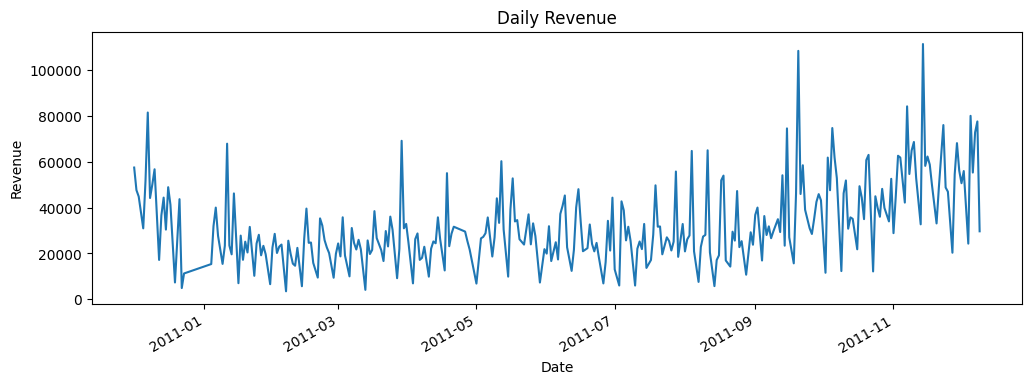

,revenue
date,
2010-12-01,57442.33
2010-12-02,47596.42
2010-12-03,44788.90
2010-12-05,30908.67
2010-12-06,51667.12


In [12]:
# Identify the one sale that was reversed by a manual entry (invoice 556444, stock 22502)
reversed_sale = (
    (df["invoice_no"].astype(str) == "556444")
    & (df["stock_code"].astype(str) == "22502")
)

# Genuine sales = not cancelled and not the reversed sale
genuine = df[(~df["is_cancelled"]) & (~reversed_sale)].copy()
print("Rows excluded as reversed sale:", reversed_sale.sum())
print("Genuine rows:", genuine.shape[0])

# Aggregate total_price to daily revenue
genuine["date"] = genuine["invoice_date"].dt.normalize()
daily = genuine.groupby("date")["total_price"].sum().rename("revenue").to_frame()

print(daily.shape)
print(daily.index.min(), daily.index.max())
print(daily["revenue"].describe())

# Plot the daily revenue series
daily["revenue"].plot(figsize=(12, 4), title="Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.show()

daily.head()

**Observation:**
- One row (invoice 556444, stock 22502) was excluded as a reversed sale, leaving 522,534 genuine rows, which matches Task 2.
- Aggregation gives 305 trading days from 2010-12-01 to 2011-12-09. The data has no Saturdays and a holiday gap around the end of December, so the series is not a complete calendar.
- Daily revenue has a mean of about 32,664 and a median of about 28,167 (std about 17,616, min about 3,440, max about 111,349). The mean being above the median indicates a right-skewed distribution driven by a few very large days.
- The line chart shows a lower and calmer level from January to August 2011, followed by a higher baseline and larger spikes from about September onward. This means the final 20% of days (our test set) will sit at a higher revenue level than most of the training period, which can hurt models that cannot extrapolate, such as Random Forest.
- The straight segment near the start of January 2011 is the holiday gap, where no sales were recorded; it is not a data error.

## Step 3: Feature engineering

**What:** Build date components, lag features and rolling-mean features for the daily revenue series.

**Why:**
- Date components (day of week, day of month, month start/end) are known in advance for any future day, so they are safe predictors and capture weekly and month-end patterns.
- Lag features (revenue of the previous trading day, 7 days ago and 14 days ago) give the model recent history. They are legitimate because those values are already known when predicting a given day.
- Rolling means summarise the recent level of sales. They are computed on the series shifted by one day, so the revenue of the day being predicted is never part of its own feature (this prevents data leakage).
- The series is reindexed to a full calendar so that `shift(7)` always means "the same weekday last week", even though Saturdays and holidays have no sales.
- `month` and `week_of_year` are created because they are standard date components, but they will be excluded from the model features in the feature selection step: the data starts in December 2010, so November is never seen in training, and the model cannot learn a pattern for it.
- Same-day quantity, unit price or invoice counts are NOT used, because they are only known after the day ends and `total_price = quantity x unit_price` (leakage).

In [13]:
# Reindex to a full daily calendar (Saturdays and holidays become NaN)
full_index = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
ts = daily.reindex(full_index)
ts.index.name = "date"

# Lag 1 = previous TRADING day (forward fill skips Saturdays and holidays)
last_known = ts["revenue"].ffill()
ts["lag_1"] = last_known.shift(1)

# Lag 7 and lag 14 = same weekday one and two weeks earlier
ts["lag_7"] = ts["revenue"].shift(7)
ts["lag_14"] = ts["revenue"].shift(14)

# Rolling means on the shifted series so that today's revenue is never included
shifted = ts["revenue"].shift(1)
ts["roll_mean_7"] = shifted.rolling(window=7, min_periods=3).mean()
ts["roll_mean_14"] = shifted.rolling(window=14, min_periods=5).mean()

# Keep only real trading days as rows
feat = ts.loc[daily.index].copy()

# Date components (known in advance for any future date)
feat["day_of_week"] = feat.index.dayofweek
feat["day_of_month"] = feat.index.day
feat["month"] = feat.index.month
feat["week_of_year"] = feat.index.isocalendar().week.astype(int)
feat["is_month_start"] = feat.index.is_month_start.astype(int)
feat["is_month_end"] = feat.index.is_month_end.astype(int)

# Rows without enough history cannot be used (no filling with averages)
print("Missing values per column before dropping:")
print(feat.isnull().sum())
rows_before = feat.shape[0]
feat = feat.dropna()
print("Rows before:", rows_before, "| after:", feat.shape[0])
print("First usable date:", feat.index.min())

feat.head(10)

Missing values per column before dropping:
revenue            0
lag_1              1
lag_7             17
lag_14            28
roll_mean_7        6
roll_mean_14      10
day_of_week        0
day_of_month       0
month              0
week_of_year       0
is_month_start     0
is_month_end       0
dtype: int64
Rows before: 305 | after: 271
First usable date: 2010-12-15 00:00:00


,revenue,lag_1,lag_7,lag_14,roll_mean_7,roll_mean_14,day_of_week,day_of_month,month,week_of_year,is_month_start,is_month_end
date,,,,,,,,,,,,
2010-12-15,30367.56,44327.11,44153.98,57442.33,41477.010000,46893.374167,2,15,12,50,0,0
2010-12-16,48868.14,30367.56,49992.52,47596.42,39179.273333,44637.143333,3,16,12,50,0,0
2010-12-17,41190.66,48868.14,56688.13,44788.90,38991.876667,44743.120000,4,17,12,50,0,0
2010-12-19,7288.47,41190.66,17125.65,30908.67,36408.965000,44443.266667,6,19,12,50,0,0
2010-12-20,25480.77,7288.47,36574.67,51667.12,34769.435000,42474.916667,0,20,12,51,0,0
2010-12-21,43643.41,25480.77,44327.11,81454.99,32920.451667,40292.720833,1,21,12,51,0,0
2010-12-22,4856.57,43643.41,30367.56,44153.98,32806.501667,37141.755833,2,22,12,51,0,0
2010-12-23,11222.29,4856.57,48868.14,49992.52,28554.670000,33866.971667,3,23,12,51,0,0
2011-01-18,17180.93,27746.68,67856.96,15324.88,31955.448333,28776.052500,1,18,1,3,0,0


**Observation:**
- Lag features behave as intended: `lag_1` of a day equals the revenue of the previous trading day (for example, `lag_1` of Sunday 2010-12-19 equals the revenue of Friday 2010-12-17, because Saturdays have no sales), and `lag_7` / `lag_14` match the revenue of the same weekday one and two weeks earlier.
- Missing values appear only in the history-based features (`lag_1`: 1, `lag_7`: 17, `lag_14`: 28, `roll_mean_7`: 6, `roll_mean_14`: 10). The date components have no missing values.
- Dropping rows without full history reduces the data from 305 to 271 trading days (34 rows removed). The removed rows are mainly at the start of the series (not enough history for the 14-day lag) and after calendar gaps such as the Christmas break, where the lagged day has no recorded sales. Missing values were not filled with averages, because that would leak information from other periods.
- The first usable date is 2010-12-15, and the series continues from 2011-01-18 after the Christmas gap.

## Step 4: Feature selection and train/test split

**What:** Choose the final feature set, then split the data 80% / 20% in time order (the first 80% of days for training, the last 20% for testing).

**Why:**
- `month` and `week_of_year` are excluded. The data starts in December 2010, so November never appears in the training period. A model cannot learn a November effect it has never seen, and the lag and rolling features already capture the rise in sales level.
- The target `revenue` and all same-day information are excluded from the features to avoid data leakage.
- The split is chronological, not random. The goal is to predict future sales, so the model must be trained on the past and tested on days that come after it. A random split would let the model see days that surround each test day, which makes the scores look better than they would be in real use.

Features used: ['lag_1', 'lag_7', 'lag_14', 'roll_mean_7', 'roll_mean_14', 'day_of_week', 'day_of_month', 'is_month_start', 'is_month_end']
Train: (216, 9) 2010-12-15 to 2011-10-06
Test : (55, 9) 2011-10-07 to 2011-12-09
Train revenue: mean = 28001.93 | max = 108364.34
Test revenue : mean = 49892.73 | max = 111348.61


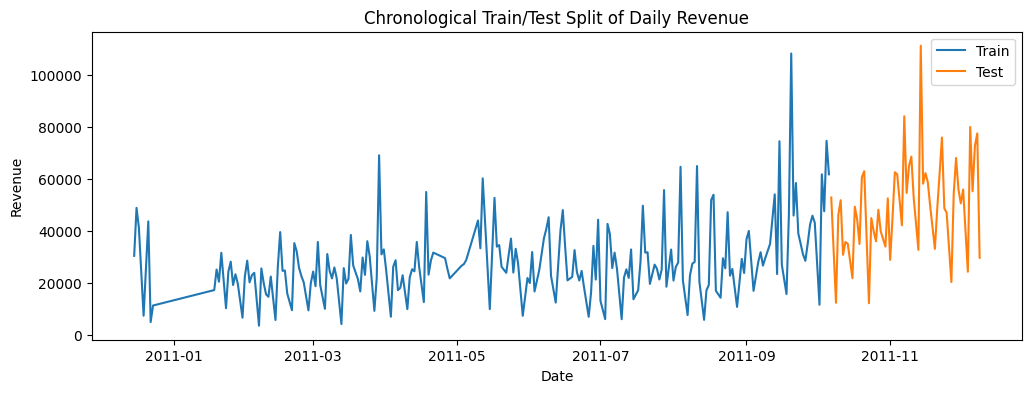

In [14]:
# Target and final features (month and week_of_year are excluded on purpose)
target = "revenue"
excluded = ["month", "week_of_year"]
features = [c for c in feat.columns if c not in [target] + excluded]
print("Features used:", features)

X = feat[features]
y = feat[target]

# Chronological 80/20 split: first 80% of days for training, last 20% for testing
split_idx = int(len(feat) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("Train:", X_train.shape, y_train.index.min().date(), "to", y_train.index.max().date())
print("Test :", X_test.shape, y_test.index.min().date(), "to", y_test.index.max().date())

# Compare the revenue level of the two periods
print("Train revenue: mean =", round(y_train.mean(), 2), "| max =", round(y_train.max(), 2))
print("Test revenue : mean =", round(y_test.mean(), 2), "| max =", round(y_test.max(), 2))

# Plot the split
plt.figure(figsize=(12, 4))
plt.plot(y_train.index, y_train, label="Train")
plt.plot(y_test.index, y_test, label="Test")
plt.title("Chronological Train/Test Split of Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.show()

**Observation:**
- The final feature set has 9 features: `lag_1`, `lag_7`, `lag_14`, `roll_mean_7`, `roll_mean_14`, `day_of_week`, `day_of_month`, `is_month_start` and `is_month_end`. `revenue`, `month` and `week_of_year` are excluded.
- The chronological split gives 216 training days (2010-12-15 to 2011-10-06) and 55 test days (2011-10-07 to 2011-12-09). The test set starts after the training set ends, so there is no overlap.
- The test period has a much higher average daily revenue (about 49,893) than the training period (about 28,002), roughly 78% higher. The maximum daily revenue is similar in both periods (about 108,364 in train and 111,349 in test), so the difference is in the typical level, not in the peaks.
- Because of this level shift, the test set is a harder, more realistic check: the model must follow a rising sales level using lag and rolling features. With only 55 test days, the metrics will also be noisy.

## Step 5: Train and evaluate the models

**What:** Evaluate three approaches on the test set using RMSE, MAE and R-squared: a naive baseline (the 7-day rolling mean), a Linear Regression baseline, and a Random Forest.

**Why:**
- The naive baseline shows how well we can do without any machine learning. A model is only useful if it beats this.
- Linear Regression is the simple baseline required by the assignment. It can follow a rising level through the lag and rolling features, but it cannot capture non-linear patterns.
- Random Forest is a tree-based model that can learn non-linear relationships and interactions, but it cannot predict values outside the range it saw in training.
- RMSE penalises large errors (important because revenue has big spikes), MAE is the average absolute error in revenue units, and R-squared shows how much of the variation is explained compared with always predicting the mean.
- All models are trained only on the training period and scored only on the test period.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate(name, y_true, y_pred):
    """Return RMSE, MAE and R2 for one model as a dictionary."""
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "RMSE": rmse, "MAE": mae, "R2": r2}

results = []

# Naive baseline: predict each test day with its 7-day rolling mean (no training needed)
naive_pred = X_test["roll_mean_7"]
results.append(evaluate("Naive (7-day rolling mean)", y_test, naive_pred))

# Linear Regression baseline
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)
results.append(evaluate("Linear Regression", y_test, lr_pred))

# Random Forest (fixed random_state for reproducible results)
rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
results.append(evaluate("Random Forest", y_test, rf_pred))

# Model comparison table
results_df = pd.DataFrame(results).round(3)
results_df

,Model,RMSE,MAE,R2
0,Naive (7-day rolling mean),17822.926,13359.108,0.049
1,Linear Regression,15155.846,11317.335,0.313
2,Random Forest,15350.235,10948.069,0.295


**Observation:**
| Model | RMSE | MAE | R2 |
|---|---|---|---|
| Naive (7-day rolling mean) | 17,823 | 13,359 | 0.049 |
| Linear Regression | 15,156 | 11,317 | 0.313 |
| Random Forest | 15,350 | 10,948 | 0.295 |

- Both machine learning models beat the naive baseline: RMSE is about 14-15% lower, and MAE is about 15% lower for Linear Regression and about 18% lower for Random Forest.
- Linear Regression has the best RMSE and R2, while Random Forest has the best MAE. The differences between them are small, and with only 55 test days they are within noise, so neither model is a clear winner.
- R2 is about 0.3 for both models, so roughly 70% of the day-to-day variation in revenue is not explained by the features. The average error (MAE of about 11,000) is roughly 22% of the mean daily revenue in the test period (about 49,893).
- A likely reason is that daily revenue contains large spikes, probably caused by a few big orders, which past revenue and calendar features cannot anticipate. This was not tested directly.
- Random Forest is selected for hyperparameter tuning because Linear Regression has no meaningful hyperparameters to tune, Random Forest has the best MAE, and it provides feature importance.

## Step 6: Feature importance and actual vs predicted values

**What:** Plot the Random Forest feature importances, and compare actual and predicted daily revenue on the test set for both models.

**Why:**
- Feature importance shows which inputs the Random Forest relies on, which is needed for the business interpretation. Lag and rolling features are strongly related to each other, so the importance may be shared between them and should be read as a rough guide, not exact credit.
- A line plot over time shows where the models follow the revenue level and where they miss spikes and dips. A scatter plot against the perfect-prediction line shows whether predictions are biased (for example, consistently too low at high revenue).

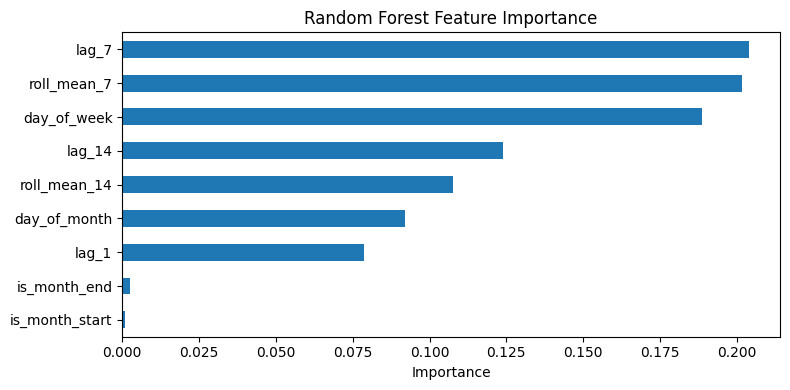

lag_7             0.204
roll_mean_7       0.202
day_of_week       0.189
lag_14            0.124
roll_mean_14      0.108
day_of_month      0.092
lag_1             0.079
is_month_end      0.003
is_month_start    0.001
dtype: float64


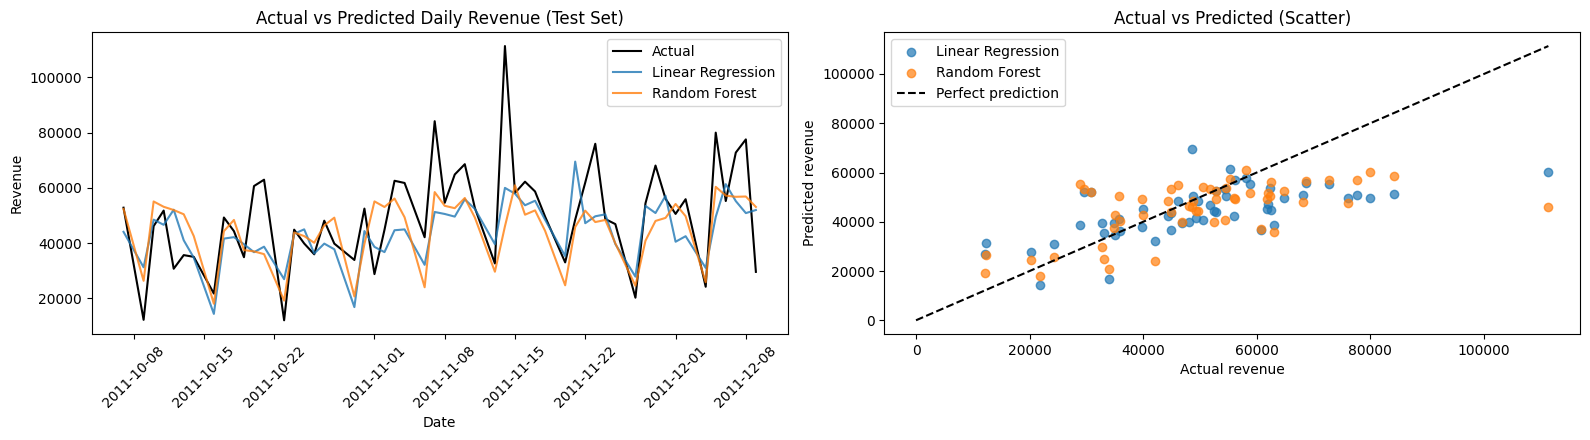

In [16]:
# Feature importance from the Random Forest
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances_sorted = importances.sort_values()

plt.figure(figsize=(8, 4))
importances_sorted.plot(kind="barh")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).round(3))

# Actual vs predicted on the test set
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

# Left: over time
axes[0].plot(y_test.index, y_test, label="Actual", color="black")
axes[0].plot(y_test.index, lr_pred, label="Linear Regression", alpha=0.8)
axes[0].plot(y_test.index, rf_pred, label="Random Forest", alpha=0.8)
axes[0].set_title("Actual vs Predicted Daily Revenue (Test Set)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Revenue")
axes[0].legend()

# Right: scatter against the perfect-prediction line
axes[1].scatter(y_test, lr_pred, label="Linear Regression", alpha=0.7)
axes[1].scatter(y_test, rf_pred, label="Random Forest", alpha=0.7)
lims = [0, max(y_test.max(), lr_pred.max(), rf_pred.max())]
axes[1].plot(lims, lims, "k--", label="Perfect prediction")
axes[1].set_title("Actual vs Predicted (Scatter)")
axes[1].set_xlabel("Actual revenue")
axes[1].set_ylabel("Predicted revenue")
axes[1].legend()
axes[0].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Observation:**
- The most important Random Forest features are `lag_7` (0.204), `roll_mean_7` (0.202) and `day_of_week` (0.189), followed by `lag_14` (0.124), `roll_mean_14` (0.108), `day_of_month` (0.092) and `lag_1` (0.079). `is_month_end` (0.003) and `is_month_start` (0.001) contribute almost nothing.
- The three most important features together account for about 60% of the total importance. The high importance of `lag_7` and `day_of_week` points to a weekly pattern in revenue. Lag and rolling features are correlated with each other, so their importance is shared between them and should be read as a rough guide, not as exact credit.
- Both models follow the general weekly rises and falls of actual revenue, but their predictions are smoother than the actual series.
- The largest spikes are not captured. For the highest-revenue days (above about 70,000, including the maximum of about 111,000) both models predict much lower values, and the scatter plot shows these points well below the perfect-prediction line. For example, the maximum day is predicted at roughly 46,000 by Random Forest and roughly 60,000 by Linear Regression (read from the plot, so approximate).
- Very low-revenue days (around 12,000 to 20,000) are slightly over-predicted. The models therefore tend to pull predictions toward the average, which is consistent with the moderate R2 of about 0.3.

## Step 7: Hyperparameter tuning (GridSearchCV with time-series cross-validation)

**What:** Search for better Random Forest settings (`n_estimators`, `max_depth`, `min_samples_leaf`) using GridSearchCV on the training data only.

**Why:**
- Default settings may overfit (trees that are too deep) or underfit. Limiting depth and requiring more samples per leaf makes the forest smoother and often generalises better on small datasets.
- Cross-validation uses `TimeSeriesSplit`: each fold trains on earlier days and validates on the days right after them. Ordinary shuffled K-fold would put future days in the training folds and reintroduce leakage.
- The test set is not used in the search. It is only used once at the end to report the final score of the tuned model.
- The scoring metric is RMSE, the same metric used to compare models earlier.
- The grid was refined once: the first search chose `min_samples_leaf=5`, the largest value in that grid, so larger values (8, 12, 20) were added in a second search, while `max_depth=3` and `n_estimators=300` were dropped because they were not among the best settings. The second search again chose `min_samples_leaf=5`, so the best value is no longer at the edge of the grid. The refinement used cross-validation results only, never test scores.
- Note: the validation folds come from the earlier, lower-revenue part of the year, so the cross-validation RMSE is not directly comparable to the test RMSE.

In [17]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Refined hyperparameter grid (3 x 2 x 4 = 24 combinations)
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 8, None],
    "min_samples_leaf": [5, 8, 12, 20],
}

# Time-series cross-validation: each fold validates on days after its training days
tscv = TimeSeriesSplit(n_splits=5)

grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

# Fit on the TRAINING data only
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV RMSE:", round(-grid.best_score_, 2))

# Top 5 parameter combinations by CV RMSE
cv_table = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score"]]
cv_table["cv_rmse"] = -cv_table["mean_test_score"]
print(cv_table.sort_values("cv_rmse").head(5)[["params", "cv_rmse"]].round(2).to_string(index=False))

# Keep only the first three results (naive, Linear Regression, Random Forest)
# so that re-running this cell never creates a duplicate tuned row
results = results[:3]

# Evaluate the tuned model once on the test set and add it to the comparison table
best_rf = grid.best_estimator_
best_pred = best_rf.predict(X_test)
results.append(evaluate("Random Forest (tuned)", y_test, best_pred))
results_df = pd.DataFrame(results).round(3)
results_df

Best parameters: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}
Best CV RMSE: 12411.66
                                                         params  cv_rmse
{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100} 12411.66
   {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 100} 12412.63
   {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 100} 12428.02
{'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200} 12497.41
   {'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 200} 12498.44


,Model,RMSE,MAE,R2
0,Naive (7-day rolling mean),17822.926,13359.108,0.049
1,Linear Regression,15155.846,11317.335,0.313
2,Random Forest,15350.235,10948.069,0.295
3,Random Forest (tuned),15131.537,11018.936,0.315


**Observation:**
- The best parameters found by GridSearchCV (with TimeSeriesSplit) are `max_depth=None`, `min_samples_leaf=5` and `n_estimators=100`, with a cross-validation RMSE of about 12,412. The same settings won in the refined grid, so `min_samples_leaf=5` is not at the edge of the search range.
- The top five combinations have almost identical CV RMSE (about 12,412 to 12,498, a spread of roughly 0.7%), so the model is not very sensitive to these settings. Using more trees (200 instead of 100) did not improve the score.
- On the test set the tuned Random Forest reaches RMSE 15,132, MAE 11,019 and R2 0.315. Compared with the default Random Forest, RMSE improves by about 1.4% and R2 rises from 0.295 to 0.315, while MAE is slightly worse (11,019 vs 10,948).
- The tuned Random Forest and Linear Regression are practically tied (RMSE 15,132 vs 15,156, R2 0.315 vs 0.313). With only 55 test days this difference is within noise, so neither can be called clearly better. Both beat the naive baseline by about 15% in RMSE.
- The cross-validation RMSE (about 12,412) is lower than the test RMSE (about 15,132) because the validation folds come from the earlier, lower-revenue part of the year, so the two numbers are not directly comparable.
- The tuned Random Forest is used as the final model because its hyperparameters were chosen with cross-validation on the training data only, and it has the best RMSE and R2 on the test set, although the margin is small.

## Step 8: Final model evaluation

**What:** Rank all models by test RMSE, plot the actual vs predicted revenue of the final (tuned Random Forest) model, and summarise its errors in business terms.

**Why:**
- The assignment asks for an actual vs predicted plot of the best model, and a clear interpretation of how wrong the predictions are in revenue units.
- The average error (bias) shows whether the model systematically under- or over-predicts. The error as a percentage of mean daily revenue tells a business user how reliable a daily forecast is.
- Looking at the highest-revenue day shows how the model behaves on the days that matter most for planning.

                        Model       RMSE        MAE     R2
0       Random Forest (tuned)  15131.537  11018.936  0.315
1           Linear Regression  15155.846  11317.335  0.313
2               Random Forest  15350.235  10948.069  0.295
3  Naive (7-day rolling mean)  17822.926  13359.108  0.049


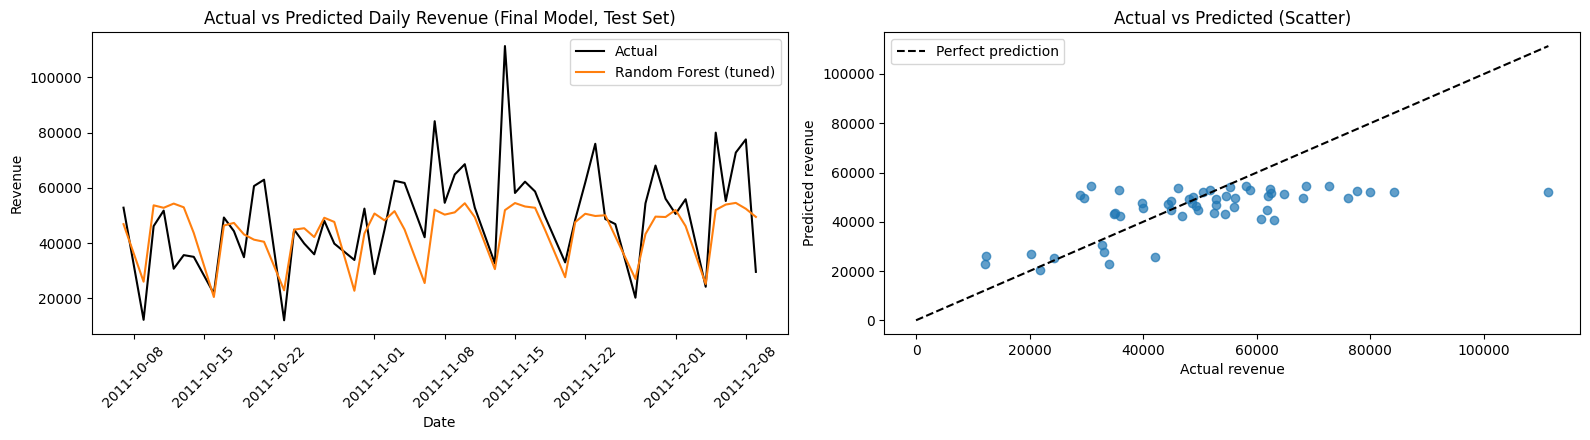

Mean error (actual - predicted): 4821.55
MAE as % of mean test revenue  : 22.1 %
Days under-predicted: 34 of 55
Peak day: 2011-11-14
Actual: 111348.61
Tuned RF prediction: 51961.21
Linear Regression prediction: 60018.62


In [18]:
# Final comparison table, sorted by test RMSE
final_table = results_df.sort_values("RMSE").reset_index(drop=True)
print(final_table)

# Predictions of the final model as a Series aligned with the test dates
final_pred = pd.Series(best_pred, index=y_test.index)

# Actual vs predicted plots for the final model
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

axes[0].plot(y_test.index, y_test, label="Actual", color="black")
axes[0].plot(y_test.index, final_pred, label="Random Forest (tuned)", color="tab:orange")
axes[0].set_title("Actual vs Predicted Daily Revenue (Final Model, Test Set)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Revenue")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].scatter(y_test, final_pred, alpha=0.7)
lims = [0, max(y_test.max(), final_pred.max())]
axes[1].plot(lims, lims, "k--", label="Perfect prediction")
axes[1].set_title("Actual vs Predicted (Scatter)")
axes[1].set_xlabel("Actual revenue")
axes[1].set_ylabel("Predicted revenue")
axes[1].legend()

plt.tight_layout()
plt.show()

# Error summary in business terms
errors = y_test - final_pred
print("Mean error (actual - predicted):", round(errors.mean(), 2))
print("MAE as % of mean test revenue  :", round(mean_absolute_error(y_test, final_pred) / y_test.mean() * 100, 1), "%")
print("Days under-predicted:", int((errors > 0).sum()), "of", len(errors))

# Behaviour on the highest-revenue day
peak_day = y_test.idxmax()
pos = y_test.index.get_loc(peak_day)
print("Peak day:", peak_day.date())
print("Actual:", round(y_test.loc[peak_day], 2))
print("Tuned RF prediction:", round(final_pred.loc[peak_day], 2))
print("Linear Regression prediction:", round(lr_pred[pos], 2))

**Observation:**
- Ranking by test RMSE: Random Forest (tuned) 15,132, Linear Regression 15,156, Random Forest (default) 15,350, Naive baseline 17,823. The tuned Random Forest has the best RMSE and R2 (0.315), while the default Random Forest has the best MAE (10,948). The top three models are very close to each other.
- The final model follows the weekly ups and downs of actual revenue, but its predictions stay in a narrow band (roughly 20,000 to 55,000, read from the plot), while actual revenue ranges from about 12,000 to 111,000. The scatter plot shows the highest days far below the perfect-prediction line.
- The mean error (actual minus predicted) is about +4,822, so the model under-predicts on average (about 9.7% of the mean test revenue). It under-predicts on 34 of 55 test days.
- The mean absolute error is about 22.1% of the mean daily revenue in the test period, so a typical daily forecast is off by roughly one fifth.
- On the highest-revenue day (2011-11-14) actual revenue was 111,349, while the tuned Random Forest predicted 51,961 and Linear Regression predicted 60,019. Both models miss the largest spike by a wide margin, so they should not be used to forecast exceptional peak days.

## Step 9: Summary of model performance and limitations

### Approach
- **Target:** daily total revenue (`total_price` summed per day) from genuine sales, i.e. non-cancelled rows excluding one sale that was reversed by a manual entry (invoice 556444).
- **Features (9):** `lag_1`, `lag_7`, `lag_14`, `roll_mean_7`, `roll_mean_14` (computed on the shifted series, so the day being predicted is never included), `day_of_week`, `day_of_month`, `is_month_start`, `is_month_end`. `month` and `week_of_year` were created but excluded because November never appears in the training period.
- **Split:** chronological 80/20 (216 training days, 55 test days), because the goal is to predict future sales. Tuning used GridSearchCV with TimeSeriesSplit on the training data only.

### Results (test set)
| Model | RMSE | MAE | R2 |
|---|---|---|---|
| Random Forest (tuned) | 15,132 | 11,019 | 0.315 |
| Linear Regression | 15,156 | 11,317 | 0.313 |
| Random Forest (default) | 15,350 | 10,948 | 0.295 |
| Naive (7-day rolling mean) | 17,823 | 13,359 | 0.049 |

- Both machine learning models reduce RMSE by about 15% compared with the naive baseline, but explain only about 30% of the variation in daily revenue (R2 of about 0.3).
- The tuned Random Forest and Linear Regression are practically tied. With 55 test days, the small differences are within noise, so no model is declared clearly better. The tuned Random Forest was chosen as the final model because its settings were selected with time-series cross-validation and it has the best RMSE and R2.
- The most important features are `lag_7`, `roll_mean_7` and `day_of_week`, which points to a weekly sales pattern.

### Business interpretation
- The model gives a rough estimate of a normal trading day, with a typical error of about 22% of daily revenue (MAE of about 11,000 on an average of about 49,900). It captures the weekly rhythm well enough to support rough planning, for example expecting quieter and busier weekdays.
- It is not reliable for very large days: it under-predicts on average (mean error of about +4,800) and missed the largest day (2011-11-14) by more than half (predicted about 52,000 vs actual about 111,000). Stock, staffing or cash-flow decisions should not rely on it for peak days.
- A useful next step for the business would be to add information that explains spikes, such as promotions, bulk orders and holiday dates.

### Limitations
- **Short history:** only about one year of data (2010-12-01 to 2011-12-09), and December 2011 is incomplete. The model cannot learn yearly seasonality, and the test period (October to early December 2011) has a much higher average revenue than the training period (about 49,900 vs about 28,000).
- **Small test set:** 55 days, so the metrics are noisy and differences between models are not reliable.
- **Spikes:** large daily spikes (probably caused by a few big orders, which was not tested directly) cannot be predicted from past revenue and calendar features. Outliers were flagged in Task 1, not removed.
- **One-day-ahead use only:** the lag and rolling features need recent actual revenue, so the model predicts the next trading day, not a long horizon.
- **Calendar gaps:** the data has no Saturdays and a holiday gap at the end of December. Rows without enough history were dropped (305 to 271 days).
- **Simple encoding:** `day_of_week` is used as a number (0 to 6), which is not ideal for Linear Regression.
- **Limited tuning:** a small grid was searched, and cross-validation folds come from the earlier, lower-revenue part of the year, so cross-validation RMSE (about 12,412) is not comparable with test RMSE (about 15,132).
- **Data consistency note (Task 1):** the genuine-sales definition used here has 522,534 rows, one fewer than Task 1 (522,535), because the manual reversal entry C556445 (stock "M") was removed in Task 1 as a non-product row, which left its original sale (invoice 556444) unreversed.

### Possible improvements (not tested)
- Predict the logarithm of revenue to reduce the effect of spikes.
- One-hot encode `day_of_week`, and add holiday and promotion indicators.
- Add lagged order counts or customer counts as features (using only past values).
- Use at least two full years of data so that yearly seasonality can be learned.